<a href="https://colab.research.google.com/github/andiarenaleandro-ux/ISSD_PH/blob/main/TP2_ANDIARENA_LEANDRO_PH_TP2_Procesamiento_PDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Procesamiento del Habla - Trabajo con archivos PDF


**Leandro Andiarena**

 Procesamiento del Habla - ISSD  
2026-10-13  
**PDF analizado:** "Tecnologías innovadoras para el rendimiento en el ciclismo competitivo" - Brito Brito, 2026 - UCACUE

## Setup Inicial

In [ ]:
# Instalacion de librerias
!pip install -q pymupdf pdfplumber camelot-py opencv-python-headless
!python -m spacy download es_core_news_sm --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.2/113.2 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 12.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 84.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
or

In [ ]:
# Imports de bibliotecas
import re
from collections import Counter
import requests
import pandas as pd
import pymupdf
import pdfplumber
import camelot
import spacy
import matplotlib.pyplot as plt

## 1 - Adquisición y metadatos

En esta primera seccion se descarga y se obtiene la metadata del documento PDF seleccionado.

PDF:  ***"Tecnologías innovadoras para el rendimiento en el ciclismo competitivo"***

In [ ]:
# url pdf seleccionado
url = "https://dspace.ucacue.edu.ec/server/api/core/bitstreams/ab91afe5-40cd-4c61-b635-2d35da80f817/content"

# Se descarga del url definido y se verifica
try:
    response = requests.get(url)
    response.raise_for_status()
    print("Éxito:", response.status_code)
except requests.exceptions.RequestException as e:
    print(f"Error de conexión o red: {e}")
    raise

Éxito: 200


In [ ]:
# Se comprueba que sea un PDF
if response.content[:4] == b"%PDF":
    # Se guarda el archivo
    with open("tecnologia_rendimiento_ciclismo.pdf", "wb") as archivo:
        archivo.write(response.content)
    print("Tamaño:", len(response.content), "bytes")
else:
    print("El archivo no es un PDF")

Tamaño: 878135 bytes


In [ ]:
# Se obtiene metadata del PDF
doc = pymupdf.open("tecnologia_rendimiento_ciclismo.pdf")

metadatos = doc.metadata

# Se imprime metadata de interes
print("Titulo:", metadatos.get('title'))
print("Autor:", metadatos.get('author'))
print("Software Utilizado:", metadatos.get('creator'))
print("Software Generador de pdf:", metadatos.get('producer'))
print("Numero de paginas:", doc.page_count)


Titulo: 
Autor: BRITO BRITO EDISSON EDMUNDO
Software Utilizado: Microsoft® Word 2016
Software Generador de pdf: Microsoft® Word 2016
Numero de paginas: 20


#### Análisis de metadata

- **Autor:** `BRITO BRITO EDISSON EDMUNDO` cargado correctamente
- **Título:** vacío. En este caso, nunca se cargó un título ya que los metadatos del PDF son declarativo
- **Creator = Producer = Microsoft® Word 2016.** el PDF fue generado directamente por Word.
- **Páginas:** 20

El origen Word confirma que el texto va a ser extraíble, no es una imagen escaneada.




---



## 2 - Analisis Estructural del Texto

Se verifica la estructura del texto, de manera de identificar caracteres separadores tipicos en PDFs.

In [ ]:
# Se extrae el texto del PDF
texto_completo = ""

for pagina in doc:
    texto_completo += pagina.get_text()

# Se muestran y verifican los separadores literales de los primeros 500 caracteres
print(repr(texto_completo[:500]))

# Se identifica longitud del texto extraido
print("Cantidad de Caracteres:", len(texto_completo))

'I \n \n \nUNIVERSIDAD CATÓLICA DE CUENCA \nComunidad Educativa al Servicio del Pueblo \nFACULTAD DE EDUCACIÓN \nCARRERA DE PEDAGOGÍA DE LA ACTIVIDAD FÍSICA Y \nDEPORTE \nTECNOLOGÍAS INNOVADORAS PARA MEJORAR EL RENDIMIENTO \nFÍSICO EN EL CICLISMO COMPETITIVO: REVISIÓN \nBIBLIOGRÁFICA \nTRABAJO DE TITULACIÓN PREVIO A LA OBTENCIÓN DEL TÍTULO \nDE LICENCIADO EN PEDAGOGÍA DE LA ACTIVIDAD FÍSICA Y \nDEPORTE \n \nAUTOR: EDISSON EDMUNDO BRITO BRITO \nDIRECTOR: LCDO. PATRICIO MARCELO BARROS PARRA, MGS   \nMACAS – ECUADOR'
Cantidad de Caracteres: 27400


In [ ]:
# Se cuentan cada carácter del texto completo
conteo_caracteres = Counter(texto_completo)

#  Se filtran caracteres de control (ASCII < 32) y el espacio de no separación (\xa0, ASCII 160)
controles_filtrados = {
    char: frec for char, frec in conteo_caracteres.items()
    if ord(char) < 32 or ord(char) == 160
}

# Imprimir la tabla con formato claro
print(f"{'Carácter (repr)':<20} | {'ASCII':<10} | {'Frecuencia':<10}")
print("-" * 48)
for char, frec in sorted(controles_filtrados.items(), key=lambda x: ord(x[0])):
    print(f"{repr(char):<20} | {ord(char):<10} | {frec:<10}")


Carácter (repr)      | ASCII      | Frecuencia
------------------------------------------------
'\n'                 | 10         | 850       


In [ ]:


# Se cuentan saltos de línea múltiples (párrafos / secciones)
saltos_dobles = len(re.findall(r'\n{2,}', texto_completo))
saltos_triples = len(re.findall(r'\n{3,}', texto_completo))
print(f"\nSaltos \\n\\n (párrafos):    {saltos_dobles}")
print(f"Saltos \\n\\n\\n (secciones): {saltos_triples}")

# Se busca Patrón artefacto Word: espacioantes de salto de línea
espacio_antes_salto = len(re.findall(r' \n', texto_completo))
print(f"\nPatrón ' \\n' (espacio antes de salto): {espacio_antes_salto}")

# Se busca Patrón '\n \n' (líneas 'en blanco' con un espacio)
lineas_blanco_con_espacio = len(re.findall(r'\n \n', texto_completo))
print(f"Patrón '\\n \\n' (líneas en blanco con espacio): {lineas_blanco_con_espacio}")


Saltos \n\n (párrafos):    0
Saltos \n\n\n (secciones): 0

Patrón ' \n' (espacio antes de salto): 848
Patrón '\n \n' (líneas en blanco con espacio): 42


#### Análisis de la Estructura y separadores

**Características del texto extraído:**
- **Longitud total:** 27.400 caracteres distribuidos en 20 páginas (~1.370 chars/página).
- **Único carácter de control detectado:** `\n` (ASCII 10), con **850 apariciones**.

**Qué separadores NO aparecen (hallazgo por ausencia):**
-  `\xa0` (NBSP) → el autor no usó espacios duros con Ctrl+Space
-  `\t` (tab) → no hay tabulaciones nativas en el texto
-  `\r` (carriage return) → sin artefactos de Windows legacy
-  `\x0c` (form feed) → PyMuPDF concatena páginas con `\n`
-  **`\n\n` (0 apariciones)** → **el autor NO usa dobles saltos para separar párrafos**


De los **850 saltos de línea**:
- **848 (99,8%)** tienen un **espacio antes** → artefacto sistemático de Word al justificar el texto
- **42** son parte del patrón `\n \n` → **estos son los verdaderos separadores de párrafo** (líneas visualmente en blanco que en realidad contienen un espacio invisible)
- Solo **7 secuencias** de 2+ espacios consecutivos → documento muy limpio, no simula tabulaciones con espacios

**Conclusión general:** el PDF es estructuralmente simple (solo `\n` como control char). Estos artefactos son invisibles a simple vista pero cambian completamente cómo hay que preprocesar el texto.

## 3 - Extraccion y Procesamiento de tablas

Se extrae la tabla que ontiene el pdf y se convierte en un dataframe. Se realiza limpieza basica

### 3.1 - Diagnostico

In [ ]:

with pdfplumber.open("tecnologia_rendimiento_ciclismo.pdf") as pdf:
    pagina_11 = pdf.pages[10]  # página 11 (donde comienza la tabla)

    # qué detecta pdfplumber en la página
    print("=== DIAGNÓSTICO DE OBJETOS EN PÁGINA 11 ===")
    print(f"Líneas detectadas:      {len(pagina_11.lines)}")
    print(f"Rectángulos:            {len(pagina_11.rects)}")
    print(f"Bordes horizontales:    {len(pagina_11.horizontal_edges)}")
    print(f"Bordes verticales:      {len(pagina_11.vertical_edges)}")
    print(f"Palabras:               {len(pagina_11.extract_words())}")
    print()

    # Probamos distintas estrategias de extracción
    configs = [
        ("Default (lines)",        {}),
        ("Text + Text",            {"vertical_strategy": "text", "horizontal_strategy": "text"}),
        ("Lines + Text",           {"vertical_strategy": "lines", "horizontal_strategy": "text"}),
        ("Text + Lines",           {"vertical_strategy": "text", "horizontal_strategy": "lines"}),
    ]

    print("=== PRUEBA DE CONFIGURACIONES ===")
    for nombre, settings in configs:
        tablas = pagina_11.extract_tables(settings)
        print(f"[{nombre:<22}] → {len(tablas)} tabla(s)")
        if tablas and tablas[0]:
            print(f"    └─ {len(tablas[0])} filas × {len(tablas[0][0])} columnas")

=== DIAGNÓSTICO DE OBJETOS EN PÁGINA 11 ===
Líneas detectadas:      0
Rectángulos:            27
Bordes horizontales:    54
Bordes verticales:      54
Palabras:               228

=== PRUEBA DE CONFIGURACIONES ===
[Default (lines)       ] → 0 tabla(s)
[Text + Text           ] → 1 tabla(s)
    └─ 69 filas × 10 columnas
[Lines + Text          ] → 0 tabla(s)
[Text + Lines          ] → 1 tabla(s)
    └─ 2 filas × 10 columnas


### 3.2 -  librerías de detección automática

In [ ]:
# Se prueba utilizando camelot
tablas = camelot.read_pdf(
    "tecnologia_rendimiento_ciclismo.pdf",
    pages="11-13",
    flavor="stream"
)

print(f"Cantidad de tablas detectadas: {tablas.n}")
print()

for i, t in enumerate(tablas):
    print(f"=== Tabla {i+1} (página {t.page}) ===")
    print(f"  Dimensiones: {t.df.shape[0]} filas × {t.df.shape[1]} columnas")
    print(f"  Precisión parsing: {t.parsing_report['accuracy']:.1f}%")
    print(f"  Whitespace: {t.parsing_report['whitespace']:.1f}%")
    print()

Cantidad de tablas detectadas: 3

=== Tabla 1 (página 11) ===
  Dimensiones: 33 filas × 12 columnas
  Precisión parsing: 86.8%
  Whitespace: 67.9%

=== Tabla 2 (página 12) ===
  Dimensiones: 41 filas × 7 columnas
  Precisión parsing: 99.3%
  Whitespace: 57.5%

=== Tabla 3 (página 13) ===
  Dimensiones: 12 filas × 6 columnas
  Precisión parsing: 99.8%
  Whitespace: 47.2%



In [ ]:
tablas_lattice = camelot.read_pdf(
    "tecnologia_rendimiento_ciclismo.pdf",
    pages="11-13",
    flavor="lattice",
    line_scale=40  # aumenta sensibilidad para líneas finas (default: 15)
)

print(f"Cantidad de tablas: {tablas_lattice.n}")
for i, t in enumerate(tablas_lattice):
    print(f"=== Tabla {i+1} (p.{t.page}) ===")
    print(f"  Dimensiones: {t.df.shape[0]} filas × {t.df.shape[1]} columnas")
    print(f"  Precisión: {t.parsing_report['accuracy']:.1f}%")

Cantidad de tablas: 0


### 3.3 - solución por coordenadas

In [ ]:
# Se plantean coordenadas de la tabla en el pdf
RUTA = "tecnologia_rendimiento_ciclismo.pdf"
ENCABEZADOS = ("Autor(es)", "Título", "Tecnología", "Objetivo", "Principales")

# Se busca la posicion X0 para cada parte
with pdfplumber.open(RUTA) as pdf:
    p11 = pdf.pages[10]
    for w in p11.extract_words():
        if w["text"] in ENCABEZADOS:
            print(f"{w['text']:<12} x0={w['x0']:.1f}  top={w['top']:.1f}")

Autor(es)    x0=77.4  top=214.5
Título       x0=136.9  top=214.5
Tecnología   x0=231.1  top=214.5
Objetivo     x0=307.1  top=214.5
Principales  x0=414.3  top=214.5


### 3.4 - limpieza y validación

In [ ]:
TOL = 3  # tolerancia en puntos para el borde de cada columna

with pdfplumber.open(RUTA) as pdf:
    # Límites de columna a partir de los encabezados de la página 11
    enc = {w["text"]: w for w in pdf.pages[10].extract_words() if w["text"] in ENCABEZADOS}
    limites = [enc[k]["x0"] for k in ENCABEZADOS]

    def es_inicio(w):
        # Un estudio empieza con "(" en la primera columna, ej: "(Torres,"
        return w["text"].startswith("(") and w["x0"] < limites[1] - TOL

    # Se recorre las páginas 11, 12 y 13 acumulando estudios
    estudios = []
    for idx in (10, 11, 12):
        pag = pdf.pages[idx]
        palabras = pag.extract_words()

        if idx == 10:
            y_min = min(w["top"] for w in palabras if es_inicio(w)) - 1  # saltea título y encabezado
        else:
            y_min = 60  # saltea el número de página

        y_max = max((r["bottom"] for r in pag.rects), default=pag.height)  # fin de la tabla
        palabras = [w for w in palabras if y_min <= w["top"] < y_max]
        palabras.sort(key=lambda w: (round(w["top"]), w["x0"]))

        for w in palabras:
            if es_inicio(w):
                estudios.append([[] for _ in range(5)])
            col = sum(w["x0"] >= lim - TOL for lim in limites) - 1
            estudios[-1][col].append(w["text"])

# DataFrame final
df = pd.DataFrame(
    [[" ".join(celda) for celda in estudio] for estudio in estudios],
    columns=["autor_anio", "titulo", "tecnologia", "objetivo", "hallazgos"],
)

print(f"DataFrame: {df.shape[0]} filas × {df.shape[1]} columnas")
print("\nCeldas vacías por columna:")
print((df == "").sum())
print("\nÚltima fila (para verificar que no se coló texto de después de la tabla):")
print(df.iloc[-1].to_dict())
df.head()

DataFrame: 15 filas × 5 columnas

Celdas vacías por columna:
autor_anio    0
titulo        0
tecnologia    0
objetivo      0
hallazgos     0
dtype: int64

Última fila (para verificar que no se coló texto de después de la tabla):
{'autor_anio': '(Gómez, 2022)', 'titulo': 'Programa de entrenamiento basado en potencia mecánica orientado a la mejora de rendimiento de un ciclista de ruta amateur.', 'tecnologia': 'Potenciómetro y pulsómetro.', 'objetivo': 'Mostrar un programa de entrenamiento basado en la utilización de dispositivos tecnológicos para medir la potencia y frecuencia cardíaca orientado a la mejora del rendimiento.', 'hallazgos': 'El uso de dispositivos tecnológicos como el pulsómetro y potenciómetro son aliados al momento de optimizar la planificación y rendimiento en el ciclismo.'}


,autor_anio,titulo,tecnologia,objetivo,hallazgos
0,"(Quishpe, Chisag, & Talavera, 2024)",La transformación digital en el deporte: El im...,"Plataformas digitales, wearables.",Analizar el impacto de las TICs en el rendimie...,Las TICs permiten ajustar mejor la carga de en...
1,"(Torres, 2021)",La variabilidad de la frecuencia cardíaca y su...,Pulsómetro.,Revisar la aplicación del pulsómetro como herr...,La variabilidad de la frecuencia cardíaca (HRV...
2,"(Sáenz, Cordero, & Moncada, 2022)",Relación de la intensidad en los entrenamiento...,Monitorización de la intensidad.,"Determinar la relación entre intensidad, condi...",La cuantificación de cargas influye en el rend...
3,"(Sanabria, Silveira, & Cortina, 2023)",Análisis bibliométrico del deporte 4.0: una re...,"Análisis de datos, Big Data",Analizar la innovación tecnológica en el depor...,Crecimiento del uso de análisis de datos para ...
4,"(García, y otros, 2025)",El impacto de la inteligencia artificial y aná...,Plataformas de análisis de datos.,Describir el uso de la IA y el análisis de dat...,La IA y el análisis de datos mejora la gestión...


In [ ]:


# Normalizar espacios en todas las celdas
df = df.map(lambda x: re.sub(r"\s+", " ", x).strip())

# Eliminar filas totalmente vacías y resetear índice
filas_antes = len(df)
df = df[(df != "").any(axis=1)].reset_index(drop=True)
print(f"Filas eliminadas por estar vacías: {filas_antes - len(df)}")

# Validaciones
print(f"Filas duplicadas: {df.duplicated().sum()}")
print(f"Celdas vacías en total: {(df == '').sum().sum()}")

#  Columna extra: año de publicación extraído del campo autor
df["anio"] = df["autor_anio"].str.extract(r"(\d{4})").astype(int)

print(f"\nDataFrame final: {df.shape[0]} filas × {df.shape[1]} columnas")
print("\nEstudios por año:")
print(df["anio"].value_counts().sort_index())

#  Ver el texto completo de una celda larga
print("\nEjemplo de celda completa (fila 0, título):")
print(df.loc[0, "titulo"])

df

Filas eliminadas por estar vacías: 0
Filas duplicadas: 0
Celdas vacías en total: 0

DataFrame final: 15 filas × 6 columnas

Estudios por año:
anio
2017    1
2021    3
2022    3
2023    2
2024    4
2025    2
Name: count, dtype: int64

Ejemplo de celda completa (fila 0, título):
La transformación digital en el deporte: El impacto de las TICs en la mejora del rendimiento deportivo y la experiencia del usuario.


,autor_anio,titulo,tecnologia,objetivo,hallazgos,anio
0,"(Quishpe, Chisag, & Talavera, 2024)",La transformación digital en el deporte: El im...,"Plataformas digitales, wearables.",Analizar el impacto de las TICs en el rendimie...,Las TICs permiten ajustar mejor la carga de en...,2024
1,"(Torres, 2021)",La variabilidad de la frecuencia cardíaca y su...,Pulsómetro.,Revisar la aplicación del pulsómetro como herr...,La variabilidad de la frecuencia cardíaca (HRV...,2021
2,"(Sáenz, Cordero, & Moncada, 2022)",Relación de la intensidad en los entrenamiento...,Monitorización de la intensidad.,"Determinar la relación entre intensidad, condi...",La cuantificación de cargas influye en el rend...,2022
3,"(Sanabria, Silveira, & Cortina, 2023)",Análisis bibliométrico del deporte 4.0: una re...,"Análisis de datos, Big Data",Analizar la innovación tecnológica en el depor...,Crecimiento del uso de análisis de datos para ...,2023
4,"(García, y otros, 2025)",El impacto de la inteligencia artificial y aná...,Plataformas de análisis de datos.,Describir el uso de la IA y el análisis de dat...,La IA y el análisis de datos mejora la gestión...,2025
5,"(Martí, Bárcena, & Nuell, 2024)",Influencia de la potencia en el rendimiento en...,Potenciómetro.,Analizar la potencia en el rendimiento en Cros...,"La potencia relativa se asocia al rendimiento,...",2024
6,"(Arteaga, 2023)",Análisis de potencia y frecuencia cardíaca med...,Potenciómetro y pulsómetro.,Conocer las zonas de potencia y frecuencia car...,A través de las zonas de entrenamiento estable...,2023
7,"(Sitko, 2021)",Estudio de la potencia como alternativa a los ...,Potenciómetro.,Comparar la utilidad de datos de potencia con ...,Las métricas de potencia en campo son más prác...,2021
8,"(Ojeda, 2017)",Utilidad del potenciómetro frente al pulsómetr...,Potenciómetro y pulsómetro.,Analizar la utilidad del potenciómetro y pulsó...,El rendimiento ciclista se logra al utilizar e...,2017
9,"(Martínez, 2024)",Entrenamiento basado en la variabilidad de la ...,Pulsómetro.,Identificar la eficacia de la variabilidad de ...,El uso del pulsómetro para identificar la vari...,2024


### Análisis de Extracción de datos tabulares



**Tabla objetivo:** "Tabla 1" del capítulo de Resultados, de 5 columnas (autor/año, título, tecnología, objetivo, hallazgos), que se extiende de la página 11 a la 13 y resume los estudios de la revisión.

**Intentos realizados :**

| Intento | Resultado | Causa del fallo |
|---|---|---|
| pdfplumber `extract_tables()` por defecto | 0 tablas | El PDF no tiene líneas vectoriales (0 `lines`, 27 `rects`): las celdas se dibujaron como rectángulos |
| pdfplumber estrategia `text` | 69×10 / 2×10 | Sobre/sub-división: trata cada línea interna de una celda como una fila |
| tabula-py | `JSONDecodeError` | Incompatibilidad entre su backend Java y el entorno Python 3.13 de Colab |
| camelot `stream` | 33×12, 41×7, 12×6 | Cada línea de texto de una celda quedó como fila y las columnas se fragmentaron |
| camelot `lattice` | 0 tablas | Mismo problema que pdfplumber: no hay líneas que detectar |
| **pdfplumber + coordenadas de palabras** | **15×5 correcto** | Reconstrucción propia a partir de `x0` y `top` |

**Solución adoptada:** en lugar de depender de la detección automática de tablas, se reconstruyó la estructura con las posiciones de las palabras:
1. Los límites de columna se tomaron de la coordenada X de los encabezados.
2. Cada estudio se identificó por un marcador de inicio: una palabra que arranca con `(` en la primera columna (ej. `(Torres,`).
3. Cada palabra se asignó a su columna según su X y se concatenó en orden de lectura, lo que resolvió las celdas multilínea.
4. La tabla se procesó página por página (11 a 13) acumulando estudios, lo que resolvió la continuación entre páginas.

**Limpieza y validación:** normalización de espacios, eliminación de filas vacías (0), verificación de duplicados (0) y de celdas vacías (0). Se agregó la columna `anio`, extraída con una expresión regular del campo autor.

**Resultados:** 15 estudios entre 2017 y 2025, con 14 de los 15 publicados de 2021 en adelante.

- La extracción de tablas en PDF no es un problema resuelto: las funciones de una línea fallan o devuelven estructuras incorrectas sin dar error.
- Las métricas de calidad automáticas pueden engañar: camelot reportó 99,3% y 99,8% de precisión en las páginas 12 y 13 con una estructura de columnas incorrecta. Esa métrica mide cuánto texto se asignó a alguna celda, no si las celdas son las correctas. Por eso se validó contra el PDF original (cantidad de filas, primera y última fila).

## 4 – Análisis de frecuencia de palabras en una página narrativa



**Objetivo:** sobre una página de texto narrativo, tokenizar y pasar a minúsculas, eliminar stopwords y puntuación, graficar las 15 palabras más frecuentes y discutir qué otros tokens consideraría stopwords.

**Herramienta:** spaCy con el modelo `es_core_news_sm`. Se procesa el texto *original* y la minúscula se aplica por token (`t.lower_`), porque pasar todo a minúsculas antes de procesar degrada el análisis gramatical del modelo.

In [ ]:
nlp = spacy.load("es_core_news_sm")

In [ ]:
### Página 15: tokenización, filtrado y top 15
texto_p15 = doc[14].get_text()
texto_p15 = re.sub(r"^\s*\d+\s*", "", texto_p15)
texto_p15 = re.sub(r"\s+", " ", texto_p15).strip()


doc_p15 = nlp(texto_p15)
tokens_p15 = [
    t.lower_ for t in doc_p15
    if not t.is_stop and not t.is_punct and not t.is_space and t.is_alpha
]
print(f"Tokens totales: {len(doc_p15)} | Tras limpieza: {len(tokens_p15)}")

Tokens totales: 316 | Tras limpieza: 144


In [ ]:
conteo = Counter(tokens_p15)
top15 = conteo.most_common(15)
freq_corte = top15[-1][1]
empatadas = [w for w, f in conteo.items() if f == freq_corte]
mostradas = {w for w, _ in top15}

print(top15)
print(f"\nFrecuencia en pagina 15: {freq_corte} | palabras con esa frecuencia: {len(empatadas)}\n")
print("Entraron al gráfico:  ", [w for w in empatadas if w in mostradas])
print("Quedaron afuera:      ", [w for w in empatadas if w not in mostradas])

[('frecuencia', 5), ('cardíaca', 5), ('estudios', 3), ('rendimiento', 3), ('variabilidad', 3), ('entrenamiento', 3), ('ciclismo', 3), ('información', 2), ('basados', 2), ('integración', 2), ('potencia', 2), ('resultados', 2), ('aplicación', 2), ('sistemática', 2), ('tecnologías', 2)]

Frecuencia en pagina 15: 2 | palabras con esa frecuencia: 14

Entraron al gráfico:   ['información', 'basados', 'integración', 'potencia', 'resultados', 'aplicación', 'sistemática', 'tecnologías']
Quedaron afuera:       ['innovadoras', 'ámbito', 'competición', 'análisis', 'datos', 'planificación']


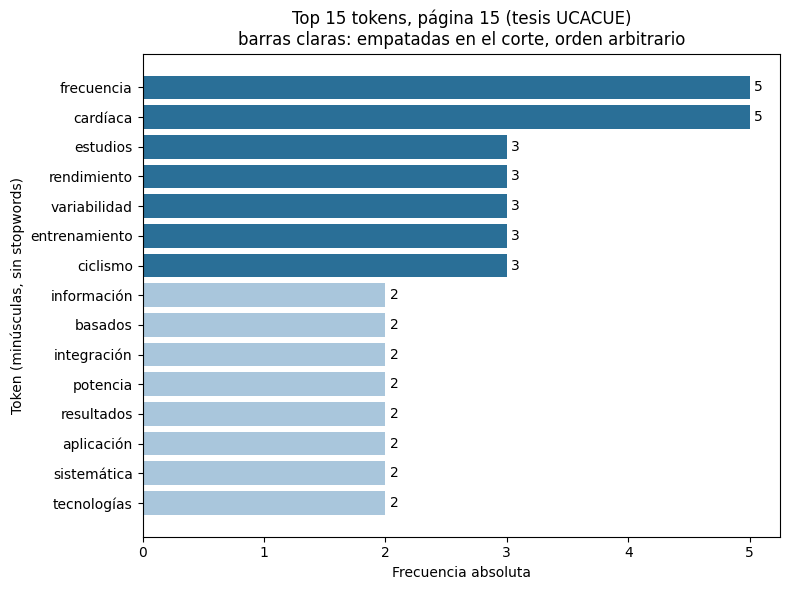

In [ ]:
palabras, frecs = zip(*top15)
colores = ["#2a6f97" if f > freq_corte else "#a9c6dc" for f in frecs]

fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh(palabras, frecs, color=colores)
ax.bar_label(barras, padding=3)
ax.invert_yaxis()
ax.set_xlabel("Frecuencia absoluta")
ax.set_ylabel("Token (minúsculas, sin stopwords)")
ax.set_title("Top 15 tokens, página 15 (tesis UCACUE)\nbarras claras: empatadas en el corte, orden arbitrario")
plt.tight_layout(); plt.show()

**Resultado:** de 316 tokens quedaron 144 (54,4 % descartado). Los más frecuentes son *frecuencia* y *cardíaca* (5), seguidos de *estudios, rendimiento, variabilidad, entrenamiento* y *ciclismo* (3). Los puestos 8 a 15 son tokens de frecuencia 2, pero hay **14 palabras empatadas** y solo 8 entran al gráfico: `Counter.most_common` desempata por orden de aparición, así que las 6 que quedaron afuera no son menos importantes, solo aparecen más tarde. Por eso las barras empatadas van en otro color.

## 5. Conclusión general

Este trabajo permitió explorar distintas herramientas de Python para procesar un PDF real: una tesis de revisión bibliográfica sobre tecnologías aplicadas al rendimiento en el ciclismo competitivo.

Con `requests` se descargó el documento y con PyMuPDF se obtuvieron sus metadatos (autor, software de origen Word 2016, 20 páginas) y su texto. El análisis estructural mostró que el PDF no separa los párrafos con `\n\n`: el texto solo contiene saltos simples, casi todos precedidos por un espacio.

Con pdfplumber se extrajo una tabla de 15 estudios y 5 columnas que ocupaba tres páginas. Las funciones automáticas de pdfplumber, tabula y camelot no la detectaron bien, porque la tabla no tiene líneas vectoriales. Se resolvió reconstruyéndola a partir de las coordenadas de las palabras y se organizó en un DataFrame de Pandas.

Finalmente, con spaCy se tokenizó una página narrativa, se eliminaron stopwords y puntuación y se graficaron las 15 palabras más frecuentes. En una página corta, muchas palabras empatan en frecuencia, por lo que el ranking es en parte arbitrario.

En conclusión, estas herramientas permiten automatizar el análisis de documentos, pero sus resultados deben validarse contra el documento original: una extracción puede parecer correcta y estar mal estructurada.

## 6. Referencias y uso de inteligencia artificial

### 6.1 Documento analizado
Brito Brito, E. E. (2026). *Tecnologías innovadoras para mejorar el rendimiento físico en el ciclismo competitivo: revisión bibliográfica* [Trabajo de titulación, Universidad Católica de Cuenca]. Repositorio institucional UCACUE.
Fuente: https://dspace.ucacue.edu.ec/server/api/core/bitstreams/ab91afe5-40cd-4c61-b635-2d35da80f817/content

### 6.2 Herramientas y bibliotecas
Python en Google Colab, con:
- **Requests**: descarga del PDF. https://requests.readthedocs.io
- **PyMuPDF**: metadatos y extracción de texto. https://pymupdf.readthedocs.io
- **pdfplumber**: extracción de palabras con coordenadas y reconstrucción de la tabla. https://github.com/jsvine/pdfplumber
- **Camelot** (y **tabula-py**, descartada): intentos de detección automática de tablas. https://camelot-py.readthedocs.io · https://github.com/chezou/tabula-py
- **Pandas**: DataFrame, limpieza y validación. https://pandas.pydata.org
- **spaCy** (modelo `es_core_news_sm`): tokenización, stopwords y puntuación. https://spacy.io/models/es
- **Matplotlib**: gráficos de frecuencias. https://matplotlib.org

### 6.3 Uso de inteligencia artificial
Utilicé **Claude (Anthropic)** como tutor y apoyo durante el trabajo, La usé para:


1. **Estructura del texto:** analizar los caracteres de control con `repr()` y expresiones regulares.
2. **Tabla:** entender por qué fallaron pdfplumber, tabula y camelot, y diseñar la reconstrucción por coordenadas de palabras.

La IA aceleró la comprensión de las herramientas, pero **no se puede tomar su salida sin verificarla**. Durante el trabajo se detectaron y corrigieron varios errores de las respuestas generadas: afirmaciones sobre el PDF que el código no respaldaba, una recomendación de preprocesamiento que empeoraba el análisis gramatical (`nlp(texto.lower())`) y un criterio de selección de página demasiado optimista. En todos los casos la corrección vino de ejecutar el código y contrastar con el documento.